# Model Comparison
Compares the four models trained on the feature-engineered data (`data/processed/model/model_features.csv`):

| Model | Notebook | Saved predictions |
|---|---|---|
| Logistic regression + TF-IDF (baseline) | `linear_regression/lr_baseline.ipynb` | `models/lr_tfidf/` |
| Logistic regression, tuned | `linear_regression/lr_tuning.ipynb` | `models/lr_tfidf_tuned/` |
| LightGBM | `lgbm_xgboost/gbm.ipynb` | `models/lgbm_xgboost/` |
| CatBoost, tuned | `catboost/catboost.ipynb` | `models/catboost/` |

All four use the same training rows, the same 5 school-grouped CV folds and the same held-out test set (`split == "test"`: 1,405 programs from 437 schools never used for training or tuning).
Every metric here is computed **in this notebook from each model's saved predictions**, so all models are measured the same way.

**Target:** `vae_positive_local` (1 = locally adjusted year-1 earnings above $23,475, 150% of the poverty line).

In [2]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, brier_score_loss, roc_curve)

MODELS_DIR = Path("../../models")
TARGET = "vae_positive_local"

lr_tuned_bundle = joblib.load(MODELS_DIR / "lr_tfidf_tuned" / "lr_tfidf_tuned_model.joblib")

# model name -> (predictions file, probability column, decision threshold used by that notebook)
MODELS = {
    "LR baseline":   (MODELS_DIR / "lr_tfidf" / "lr_tfidf_predictions.csv", "p_vae_lr", 0.5),
    "LR tuned":      (MODELS_DIR / "lr_tfidf_tuned" / "lr_tfidf_tuned_predictions.csv", "p_vae_lr_tuned",
                      lr_tuned_bundle["threshold"]),
    "LightGBM":      (MODELS_DIR / "lgbm_xgboost" / "lgbm_predictions.csv", "p_vae_gbm", 0.5),
    "CatBoost":      (MODELS_DIR / "catboost" / "catboost_predictions.csv", "p_vae_catboost", 0.5),
}

preds = {}
for name, (path, col, thr) in MODELS.items():
    p = pd.read_csv(path, dtype={"cipcode": str})
    preds[name] = p.rename(columns={col: "prob"})[["unitid", "cipcode", "control", "split", TARGET, "prob", "p_vae_oof"]]
    print(f"{name:12s} threshold {thr:.2f} | rows {len(p):,}")

# All four files must describe the same programs in the same split
keys = {name: set(zip(p["unitid"], p["cipcode"], p["split"])) for name, p in preds.items()}
assert all(k == keys["LR baseline"] for k in keys.values()), "Prediction files don't line up"
print("\nAll prediction files cover the same programs and splits.")

LR baseline  threshold 0.50 | rows 26,678
LR tuned     threshold 0.51 | rows 26,678
LightGBM     threshold 0.50 | rows 26,678
CatBoost     threshold 0.50 | rows 26,678

All prediction files cover the same programs and splits.


## 1. Held-out test set
The number to report: each model scored once on programs from schools it never saw. "Always meets" is the bar to beat
(78% accuracy by always predicting the majority class).

In [3]:
def metrics(y, prob, thr):
    pred = (prob >= thr).astype(int)
    return {"threshold": thr, "accuracy": accuracy_score(y, pred), "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred), "f1": f1_score(y, pred), "roc_auc": roc_auc_score(y, prob),
            "pr_auc": average_precision_score(y, prob), "brier": brier_score_loss(y, prob),
            "false_pos": int(((pred == 1) & (y == 0)).sum()), "false_neg": int(((pred == 0) & (y == 1)).sum())}

test_rows = {}
for name, p in preds.items():
    t = p[p["split"] == "test"]
    test_rows[name] = metrics(t[TARGET].astype(int), t["prob"], MODELS[name][2])

t = preds["LR baseline"].query("split == 'test'")
y_test = t[TARGET].astype(int)
test_rows["Always 'meets' (dummy)"] = metrics(y_test, np.ones(len(y_test)), 0.5) | {"roc_auc": 0.5, "pr_auc": y_test.mean()}

test_results = pd.DataFrame(test_rows).T.sort_values("roc_auc", ascending=False)
print(f"Test programs: {len(y_test):,} | pass rate {y_test.mean():.1%}")
test_results.round(3)

Test programs: 1,405 | pass rate 78.4%


,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc,brier,false_pos,false_neg
LightGBM,0.50,0.933,0.967,0.947,0.957,0.971,0.991,0.054,36.0,58.0
CatBoost,0.50,0.932,0.967,0.946,0.956,0.970,0.991,0.053,36.0,59.0
LR tuned,0.51,0.913,0.941,0.948,0.945,0.961,0.988,0.061,65.0,57.0
LR baseline,0.50,0.893,0.974,0.887,0.929,0.957,0.987,0.083,26.0,124.0
Always 'meets' (dummy),0.50,0.784,0.784,1.000,0.879,0.500,0.784,0.216,304.0,0.0


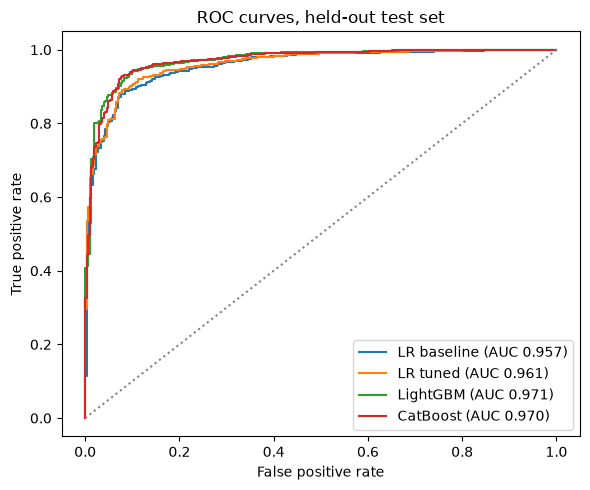

In [4]:
fig, ax = plt.subplots(figsize=(6, 5))
for name, p in preds.items():
    t = p[p["split"] == "test"]
    fpr, tpr, _ = roc_curve(t[TARGET].astype(int), t["prob"])
    ax.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(t[TARGET].astype(int), t['prob']):.3f})")
ax.plot([0, 1], [0, 1], linestyle=":", color="grey")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC curves, held-out test set")
ax.legend()
plt.tight_layout()
plt.show()

## 2. Cross-validation (out-of-fold, training rows)
Each training program's `p_vae_oof` comes from a model that didn't see its school. Same 5 folds for every model.
Scores here are slightly optimistic for the tuned models, because their settings were chosen on these folds.

In [5]:
cv_rows = {}
for name, p in preds.items():
    tr = p[p["split"] == "train"]
    cv_rows[name] = metrics(tr[TARGET].astype(int), tr["p_vae_oof"], MODELS[name][2])
cv_results = pd.DataFrame(cv_rows).T.sort_values("roc_auc", ascending=False)
cv_results.round(3)

,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc,brier,false_pos,false_neg
CatBoost,0.50,0.919,0.948,0.948,0.948,0.953,0.984,0.062,228.0,229.0
LightGBM,0.50,0.918,0.949,0.946,0.948,0.951,0.983,0.063,224.0,236.0
LR tuned,0.51,0.911,0.932,0.956,0.944,0.944,0.979,0.067,305.0,195.0
LR baseline,0.50,0.888,0.959,0.896,0.926,0.942,0.979,0.086,170.0,459.0


## 3. Fairness by school type (held-out test set)
Recall by school type shows whether good programs at some kinds of schools get overlooked more often.

In [6]:
rows = []
for name, p in preds.items():
    t = p[p["split"] == "test"]
    thr = MODELS[name][2]
    for grp, g in t.groupby("control"):
        y = g[TARGET].astype(int)
        pred = (g["prob"] >= thr).astype(int)
        rows.append({"model": name, "control": grp, "programs": len(g), "actual pass": y.mean(),
                     "mean probability": g["prob"].mean(), "predicted pass": pred.mean(),
                     "precision": precision_score(y, pred, zero_division=0), "recall": recall_score(y, pred),
                     "roc_auc": roc_auc_score(y, g["prob"]) if y.nunique() > 1 else np.nan})
fairness = pd.DataFrame(rows).set_index(["control", "model"]).sort_index()
fairness.round(3)

programs  actual pass  mean probability  \
control            model                                                  
Private for-profit CatBoost          512        0.529             0.474   
                   LR baseline       512        0.529             0.412   
                   LR tuned          512        0.529             0.540   
                   LightGBM          512        0.529             0.486   
Private non-profit CatBoost           80        0.800             0.735   
                   LR baseline        80        0.800             0.586   
                   LR tuned           80        0.800             0.736   
                   LightGBM           80        0.800             0.738   
Public             CatBoost          813        0.942             0.926   
                   LR baseline       813        0.942             0.866   
                   LR tuned          813        0.942             0.932   
                   LightGBM          813        0.942             0.933   

                                predicted pass  precision  recall  roc_auc  
control            model                                                    
Private for-profit CatBoost              0.482      0.947   0.863    0.961  
                   LR baseline           0.414      0.962   0.753    0.941  
                   LR tuned              0.535      0.869   0.878    0.947  
                   LightGBM              0.484      0.948   0.867    0.963  
Private non-profit CatBoost              0.762      0.934   0.891    0.910  
                   LR baseline           0.588      0.936   0.688    0.816  
                   LR tuned              0.750      0.867   0.812    0.807  
                   LightGBM              0.762      0.918   0.875    0.881  
Public             CatBoost              0.947      0.975   0.980    0.936  
                   LR baseline           0.915      0.980   0.952    0.924  
                   LR tuned              0.953      0.973   0.984    0.936  
                   LightGBM              0.947      0.977   0.982    0.939

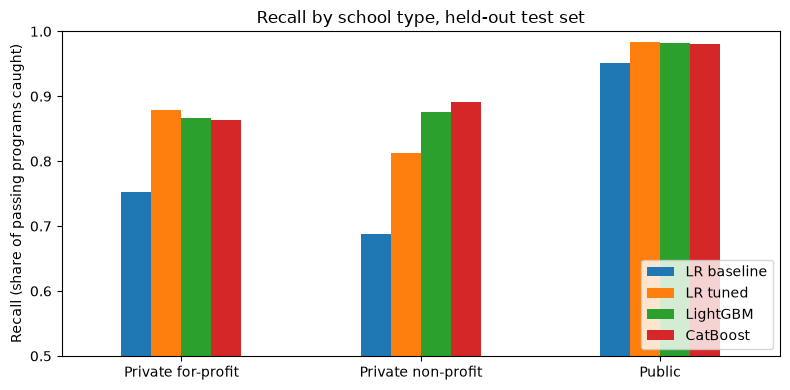

In [7]:
recall_by_type = fairness["recall"].unstack("model")[list(MODELS)]
recall_by_type.plot.bar(figsize=(8, 4), rot=0)
plt.ylabel("Recall (share of passing programs caught)")
plt.xlabel("")
plt.title("Recall by school type, held-out test set")
plt.ylim(0.5, 1.0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 4. Calibration (held-out test set)
The model's probability becomes the 40% earnings part of the Opportunity Score, so a predicted 0.8 should mean about
80% of such programs pass. A mean probability close to the actual pass rate and a low Brier score mean the
probabilities can be used directly.

In [8]:
calib = pd.DataFrame({name: {"mean probability": p.loc[p["split"] == "test", "prob"].mean(),
                             "actual pass rate": p.loc[p["split"] == "test", TARGET].mean(),
                             "brier": test_rows[name]["brier"]}
                      for name, p in preds.items()}).T
calib["gap (points)"] = (calib["mean probability"] - calib["actual pass rate"]) * 100
calib.round(3)

,mean probability,actual pass rate,brier,gap (points)
LR baseline,0.685,0.784,0.083,-9.888
LR tuned,0.778,0.784,0.061,-0.547
LightGBM,0.759,0.784,0.054,-2.468
CatBoost,0.750,0.784,0.053,-3.332


## 5. Before vs. after feature engineering
"Before" numbers come from each notebook's previous version (raw ETPL merge, each notebook's own drop list and
`GroupKFold` split on all 7,024 labeled programs). "After" is the out-of-fold CV above. The CV numbers aren't
perfectly comparable (after = 80% of the labeled programs and the shared folds), so the held-out test column is the
fair measure going forward.

In [9]:
before = pd.DataFrame({
    "LR baseline": {"CV F1 (before)": 0.925, "CV ROC-AUC (before)": 0.947},
    "LR tuned":    {"CV F1 (before)": 0.945, "CV ROC-AUC (before)": 0.949},
    "LightGBM":    {"CV F1 (before)": 0.952, "CV ROC-AUC (before)": 0.960},
    "CatBoost":    {"CV F1 (before)": 0.953, "CV ROC-AUC (before)": 0.962},
}).T
after = pd.DataFrame({"CV F1 (after)": cv_results["f1"], "CV ROC-AUC (after)": cv_results["roc_auc"],
                      "Test F1": test_results["f1"], "Test ROC-AUC": test_results["roc_auc"]})
before.join(after).loc[list(MODELS)].round(3)

,CV F1 (before),CV ROC-AUC (before),CV F1 (after),CV ROC-AUC (after),Test F1,Test ROC-AUC
LR baseline,0.925,0.947,0.926,0.942,0.929,0.957
LR tuned,0.945,0.949,0.944,0.944,0.945,0.961
LightGBM,0.952,0.960,0.948,0.951,0.957,0.971
CatBoost,0.953,0.962,0.948,0.953,0.956,0.970


## Takeaways

**1. The tree models win, and LightGBM and CatBoost are tied.** On the held-out test set (1,405 programs, 437 unseen schools):

| Model | F1 | ROC-AUC | Precision | Recall | False pos. | False neg. |
|---|---|---|---|---|---|---|
| **LightGBM** | **0.957** | **0.971** | 0.967 | 0.947 | 36 | 58 |
| **CatBoost** | 0.956 | 0.970 | 0.967 | 0.946 | 36 | 59 |
| LR tuned | 0.945 | 0.961 | 0.941 | 0.948 | 65 | 57 |
| LR baseline | 0.929 | 0.957 | 0.974 | 0.887 | 26 | 124 |
| Always "meets" | 0.879 | 0.500 | 0.784 | 1.000 | 304 | 0 |

LightGBM and CatBoost differ by 0.001 and made nearly identical errors; cross-validation agrees (ROC-AUC 0.951 vs. 0.953). **LightGBM is the practical pick**: same accuracy, and it trains in seconds instead of ~25 minutes for the CatBoost search.

**2. Every model scores higher on the test set than in cross-validation** (e.g. LightGBM ROC-AUC 0.951 CV → 0.971 test), so the CV numbers were not optimistic and the models generalize to new schools.

**3. Fairness: the tree models and tuned LR close most of the baseline's for-profit gap.** For-profit recall on the test set: LR baseline 0.753, LR tuned 0.878, LightGBM 0.867, CatBoost 0.863. Non-profit recall is the weakest point for the LR models (0.69 baseline, 0.81 tuned) and better for the trees (0.88–0.89), though only 80 non-profit programs are in the test set. Public programs are 0.95–0.98 for every model.

**4. Calibration: tuned LR has the most honest probabilities; the tree models need calibrating.** Mean predicted probability vs. actual pass rate (78.4%): LR tuned 77.8% (−0.5 points), LightGBM 75.9% (−2.5), CatBoost 75.0% (−3.3), LR baseline 68.5% (−9.9). The tree models have the best Brier scores (0.053–0.054) because they rank well, but class weighting shifts their probabilities down a few points. **Calibrate the chosen model's probabilities** (e.g. `CalibratedClassifierCV`, isotonic, on the out-of-fold predictions) before using them as the 40% earnings part of the Opportunity Score.

**5. Before vs. after feature engineering:** cross-validated ROC-AUC dipped by 0.005–0.009 for each model. The "after" CV trains on only the 80% training split, the folds changed, and features with possible leakage (5-year benchmarks, duplicate tuition columns) were removed, so the drop doesn't mean the models got worse. The held-out test scores are the first unbiased numbers and are higher than every previous CV score. The model ranking is unchanged.

**Recommendation:** use **LightGBM** for the earnings part of the Opportunity Score, with calibrated probabilities. Keep **tuned LR** as the explainable reference model (its coefficients and calibration are easy to present), and report test-set metrics and recall by school type in the final presentation.
